# 02 · CNN：普通几何增强与精选增强

使用相同的两层卷积网络、优化器、随机种子和训练预算，只保留两组对照：

1. **CNN geometric**：旋转 ±10°、水平／垂直平移 ±2 像素、缩放 0.85–1.15。
2. **CNN enhanced**：在几何增强上加入训练内部验证集选出的增强组合。

每组均执行作业规定的两个 trial。增强方案在每个 trial 内独立选择，不能用另一 trial 的训练／验证结果替本 trial 调参，因为两组数据互为测试集。探索阶段的完整候选结果不在本 notebook 展示；`cnn_config.json` 只保存最终选定的设置。

所有设置在最终测试前冻结。每次先用 1,600 张拟合、400 张验证，通过验证 loss 选择 epoch，再重新初始化并用本 trial 的全部 2,000 张训练图像训练选定轮数。

In [1]:
import json
import os
import time
import numpy as np
import pandas as pd
import torch
from IPython.display import display

from data_utils import ROOT, load_data, get_trial, validation_indices, output_folder, SEED
from plot_utils import plot_training_split, plot_history
from evaluation import save_json, evaluate_predictions, save_method_summary, compare_methods
from cnn_utils import SimpleCNN, plot_augmentation, train_cnn, fit_full_training_set, predict_cnn, load_cnn_model

torch.set_num_threads(min(4, os.cpu_count() or 1))
with open(ROOT / "cnn_config.json", encoding="utf-8") as stream:
    experiment = json.load(stream)
config = experiment["training"]
print("PyTorch:", torch.__version__, "Device:", config["device"])
print(SimpleCNN())
print("Parameters:", sum(p.numel() for p in SimpleCNN().parameters()))
print("Geometric augmentation:", experiment["geometric"])
for trial in [1, 2]:
    print("Selected enhanced policy, trial", trial, ":", experiment["enhanced"][str(trial)])

PyTorch: 2.14.1+cpu Device: cpu
SimpleCNN(
  (features): Sequential(
    (0): Conv2d(1, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=1568, out_features=64, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.3, inplace=False)
    (4): Linear(in_features=64, out_features=10, bias=True)
  )
)
Parameters: 105866
Geometric augmentation: {'rotation': 10, 'translation': 2, 'scale_min': 0.85, 'scale_max': 1.15, 'shear': 0}
Selected enhanced policy, trial 1 : {'rotation': 10, 'translation': 2, 'scale_min': 0.85, 'scale_max': 1.15, 'shear': 0, 'elastic_probability': 0.6, 'elastic_strength': 1.0, 'elastic_sigma': 4}
Sel

## 1. 最终增强方案的示例

只显示训练图像的原图、几何增强和最终增强效果。只保存入选方案的示意图；不是所有候选实验的结果。增强按概率应用，因此部分样例可能只发生几何变化。验证和测试都不增强。

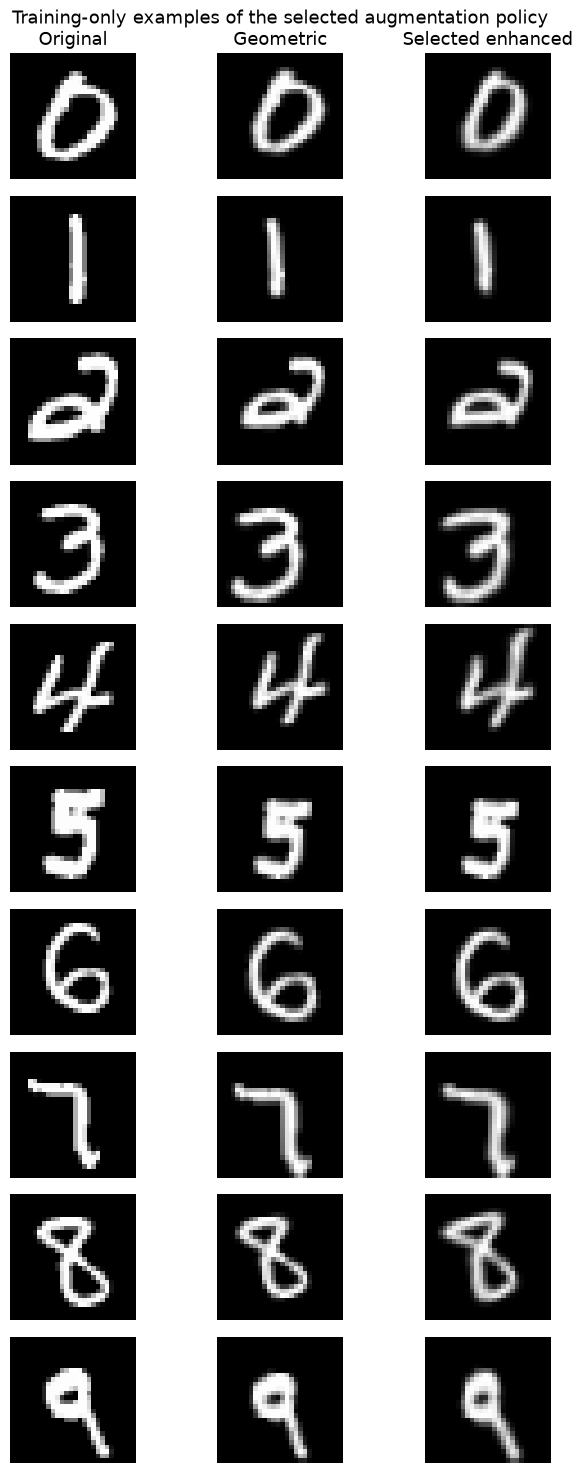

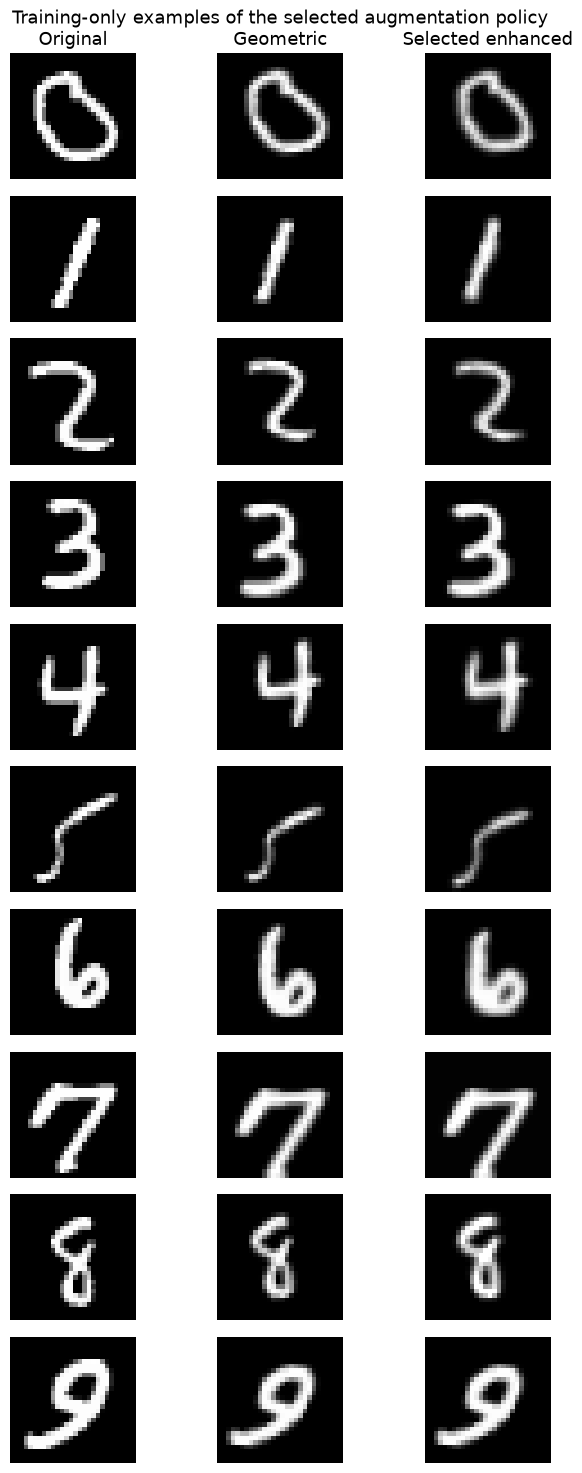

In [2]:
data = load_data()
for trial in [1, 2]:
    X_train, y_train, _, _ = get_trial(data, trial)
    plot_augmentation(X_train, y_train, output_folder("cnn_enhanced", trial),
                      experiment["enhanced"][str(trial)], seed=SEED)

## 2. 两组最终对照，各完成两个 trial

两组的训练预算相同：最多 50 个 epoch，连续 10 个 epoch 验证 loss 未改善时早停。`history.csv` 每个 epoch 更新，记录训练／验证 loss、准确率和累计耗时。

训练曲线在启用 dropout 和增强时计算；验证曲线在关闭 dropout、无增强时计算。最终拟合使用全部 2,000 张训练图像，记录单独的训练曲线，不把训练 loss 写成验证 loss。

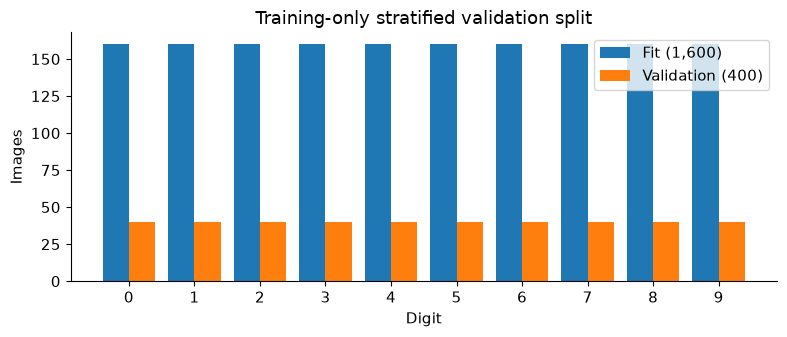


 CNN geometric Trial 1


Epoch 01: loss 2.2249/1.9638, accuracy 0.186/0.440


Epoch 02: loss 1.7843/1.1835, accuracy 0.398/0.690


Epoch 03: loss 1.3696/0.7702, accuracy 0.522/0.792


Epoch 04: loss 1.1967/0.5413, accuracy 0.584/0.848


Epoch 05: loss 1.0167/0.4693, accuracy 0.671/0.880


... (41 outputs left out)

Epoch 47: loss 0.2197/0.0507, accuracy 0.931/0.980


Epoch 48: loss 0.2368/0.0674, accuracy 0.925/0.983


Epoch 49: loss 0.2322/0.0514, accuracy 0.922/0.980


Epoch 50: loss 0.2302/0.0491, accuracy 0.925/0.985


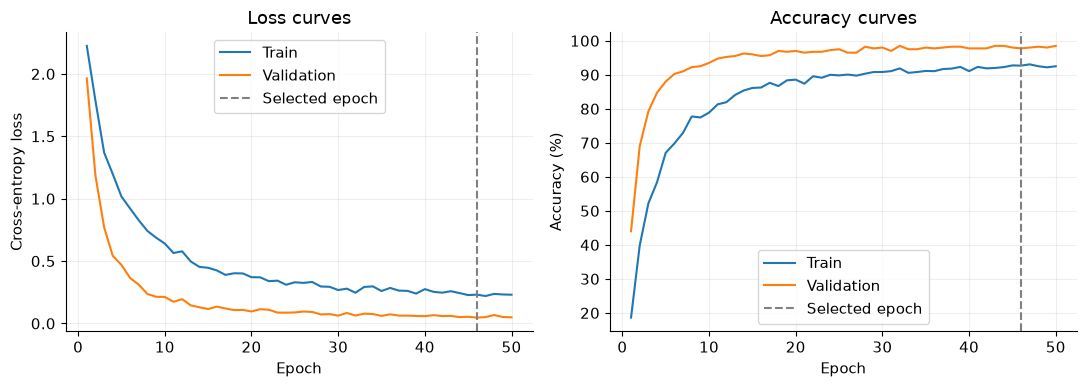

Final fit on all 2,000 training images; selected epochs: 46


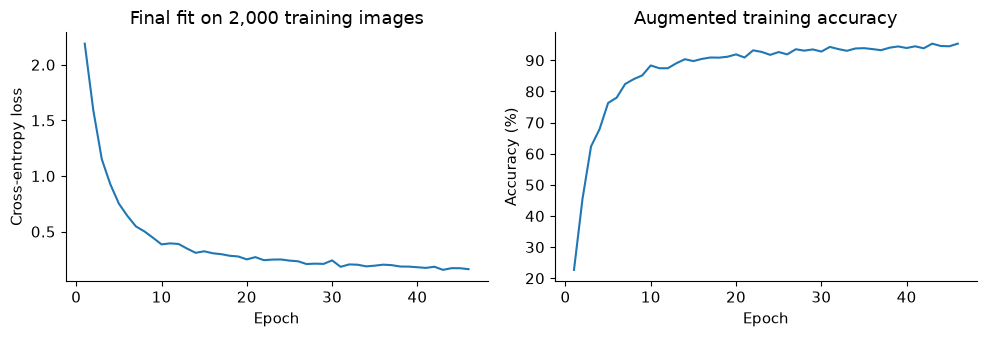

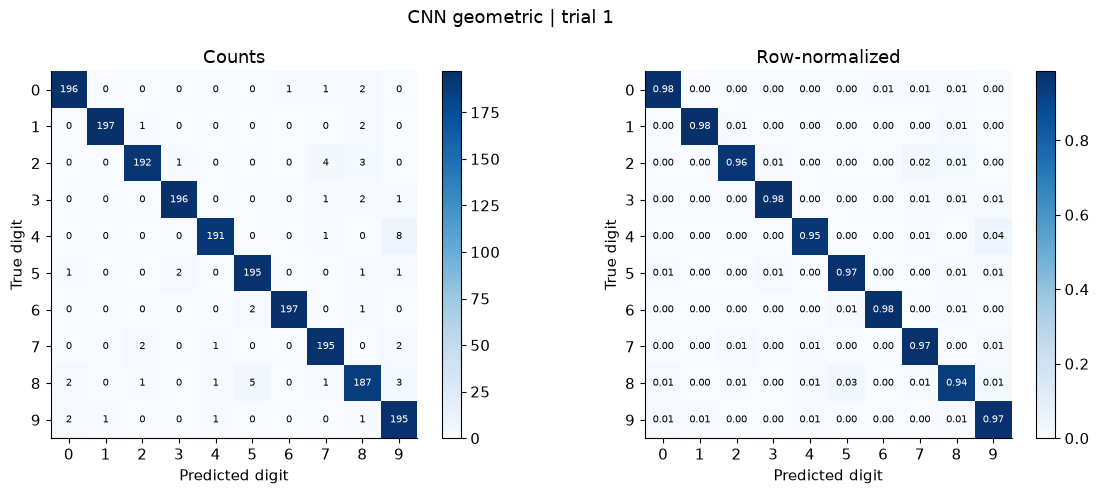

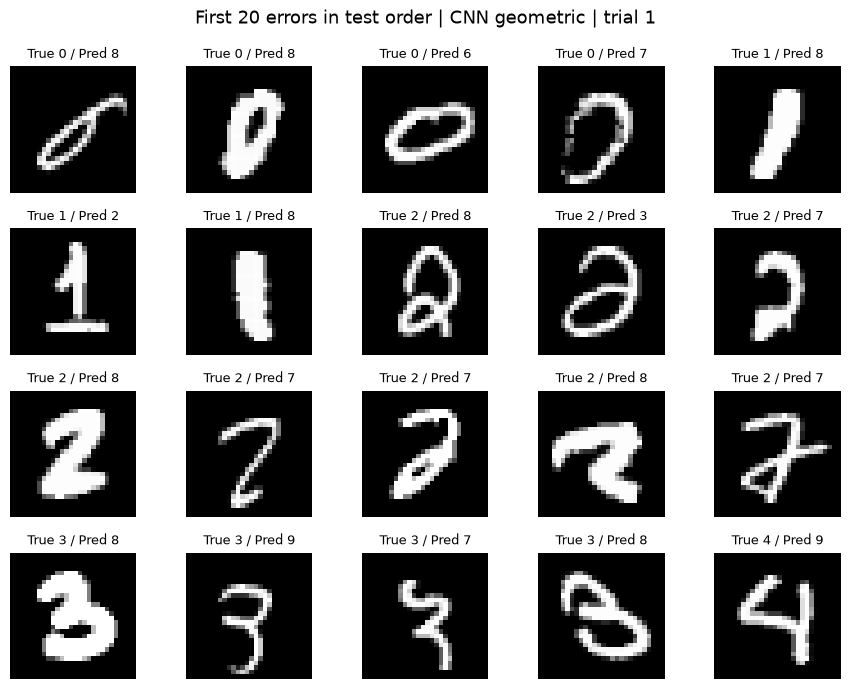

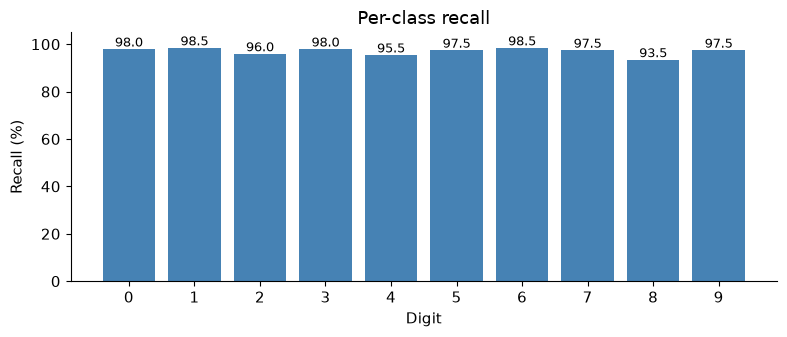

CNN geometric trial 1 accuracy = 0.9705


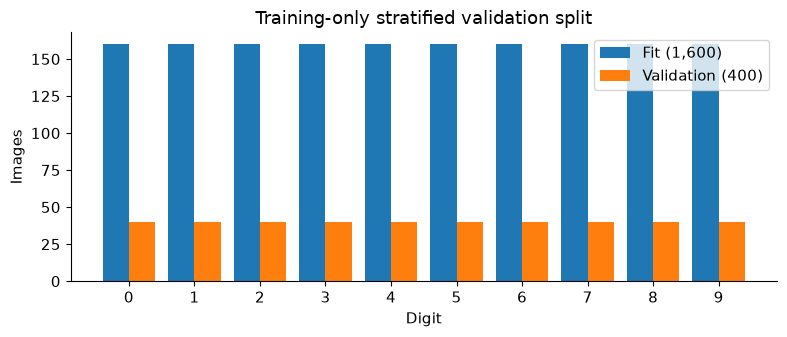


 CNN geometric Trial 2


Epoch 01: loss 2.1904/1.8161, accuracy 0.222/0.487


Epoch 02: loss 1.5909/0.9452, accuracy 0.511/0.708


Epoch 03: loss 1.2532/0.6593, accuracy 0.591/0.818


Epoch 04: loss 0.9860/0.5154, accuracy 0.668/0.840


Epoch 05: loss 0.8822/0.4034, accuracy 0.714/0.880


... (26 outputs left out)

Epoch 32: loss 0.1709/0.1203, accuracy 0.948/0.965


Epoch 33: loss 0.1868/0.1261, accuracy 0.938/0.963


Epoch 34: loss 0.1955/0.1095, accuracy 0.938/0.968


Epoch 35: loss 0.1761/0.1044, accuracy 0.946/0.963
Early stopping. Selected epoch: 25


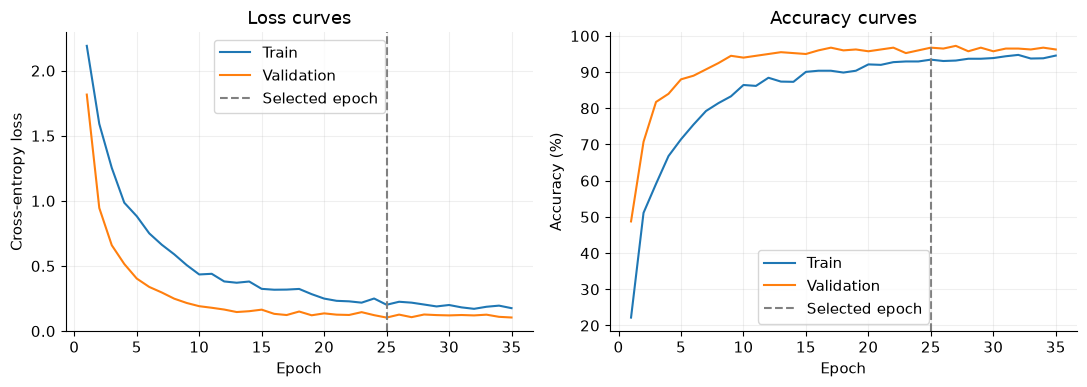

Final fit on all 2,000 training images; selected epochs: 25


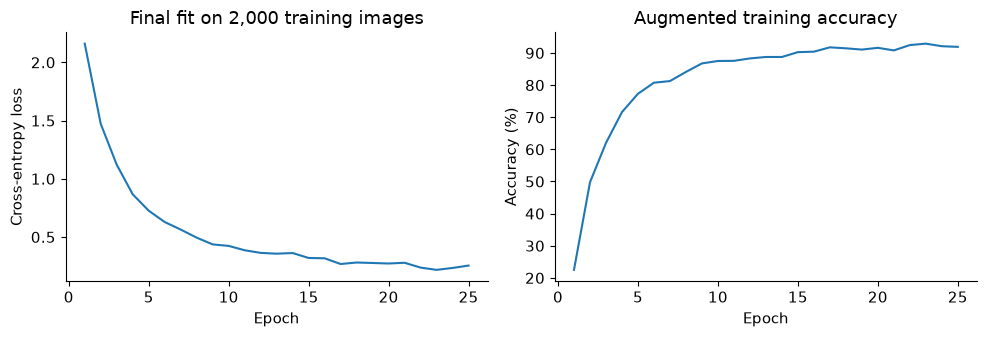

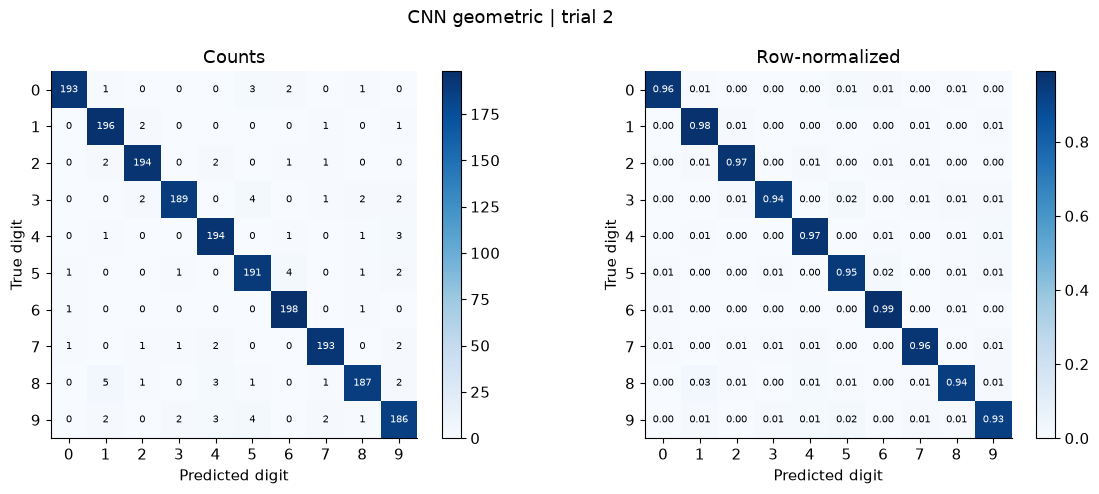

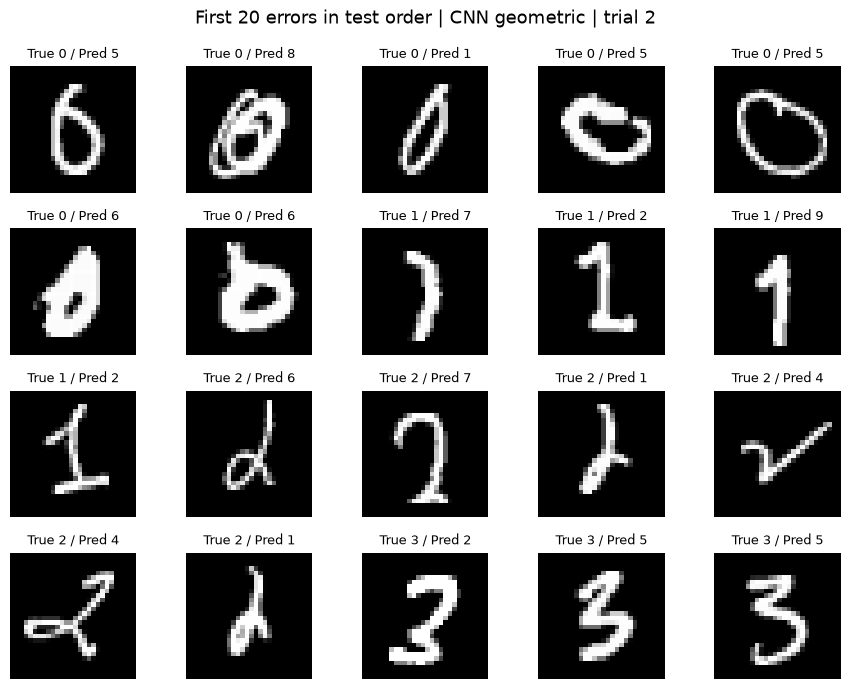

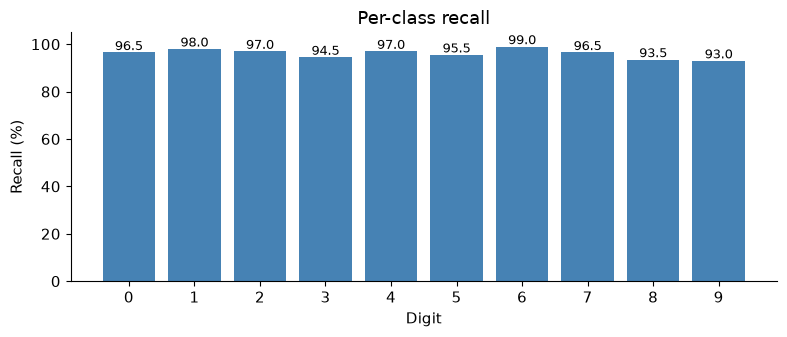

CNN geometric trial 2 accuracy = 0.9605


,method,mean_accuracy,std_accuracy,mean_macro_f1,mean_train_seconds,mean_predict_seconds
0,CNN geometric,0.9655,0.007071,0.965516,70.675925,0.245657


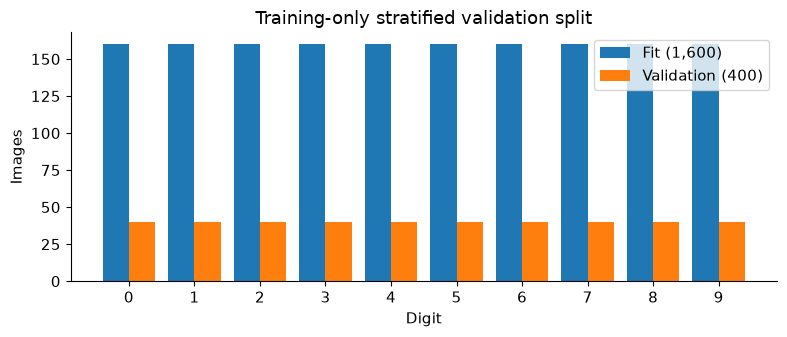


 CNN enhanced Trial 1


Epoch 01: loss 2.2280/1.9578, accuracy 0.188/0.453


Epoch 02: loss 1.8087/1.2042, accuracy 0.381/0.662


Epoch 03: loss 1.4144/0.7896, accuracy 0.502/0.782


Epoch 04: loss 1.2454/0.5768, accuracy 0.576/0.860


Epoch 05: loss 1.0598/0.4800, accuracy 0.649/0.880


... (41 outputs left out)

Epoch 47: loss 0.2306/0.0560, accuracy 0.924/0.985


Epoch 48: loss 0.2624/0.0498, accuracy 0.916/0.983


Epoch 49: loss 0.2536/0.0550, accuracy 0.918/0.983


Epoch 50: loss 0.2472/0.0503, accuracy 0.920/0.985


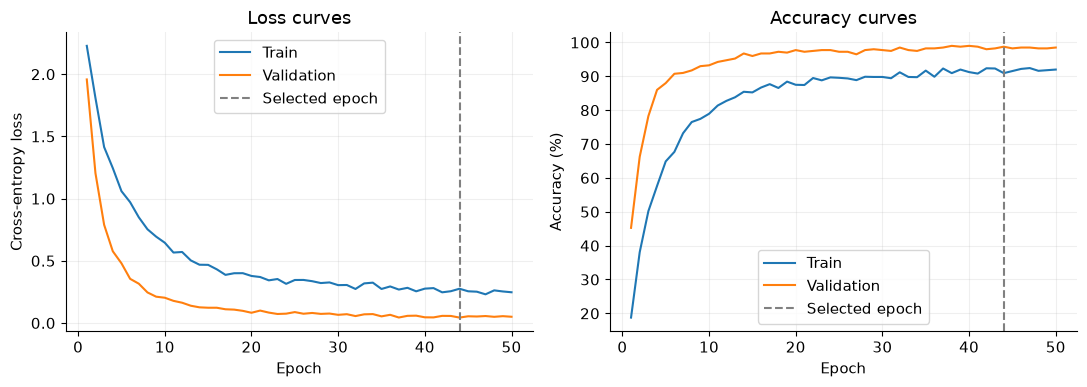

Final fit on all 2,000 training images; selected epochs: 44


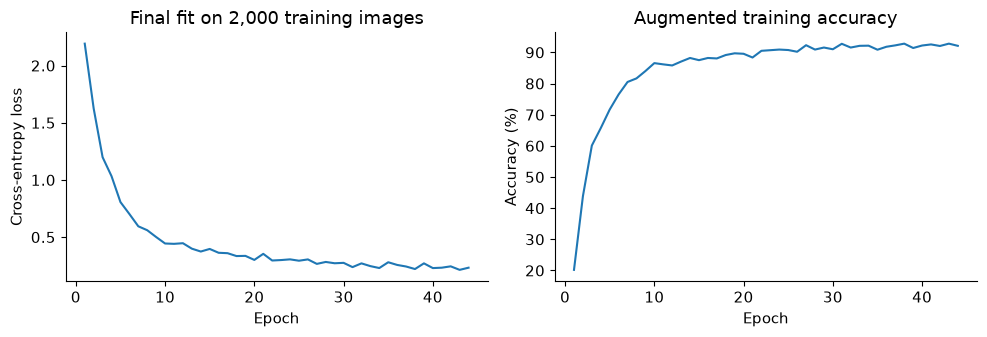

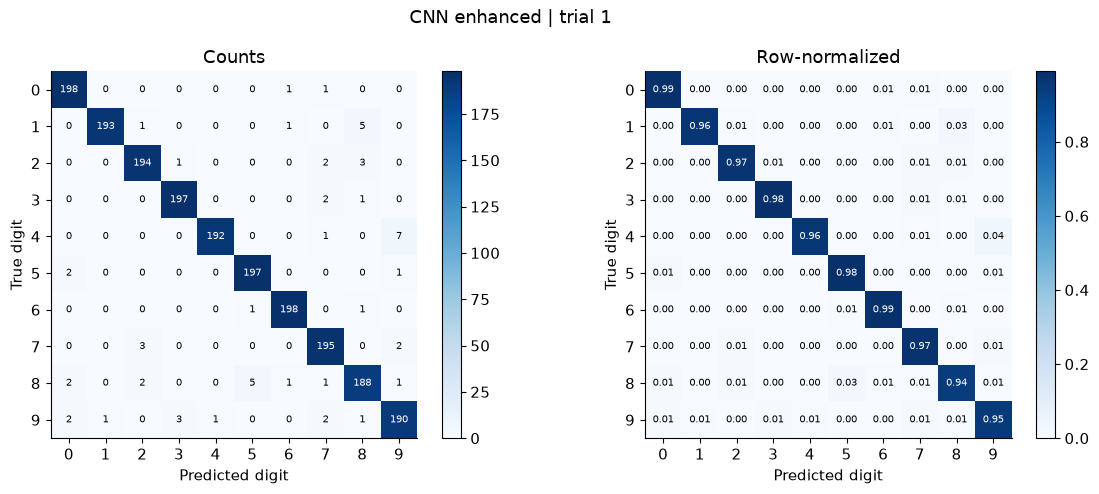

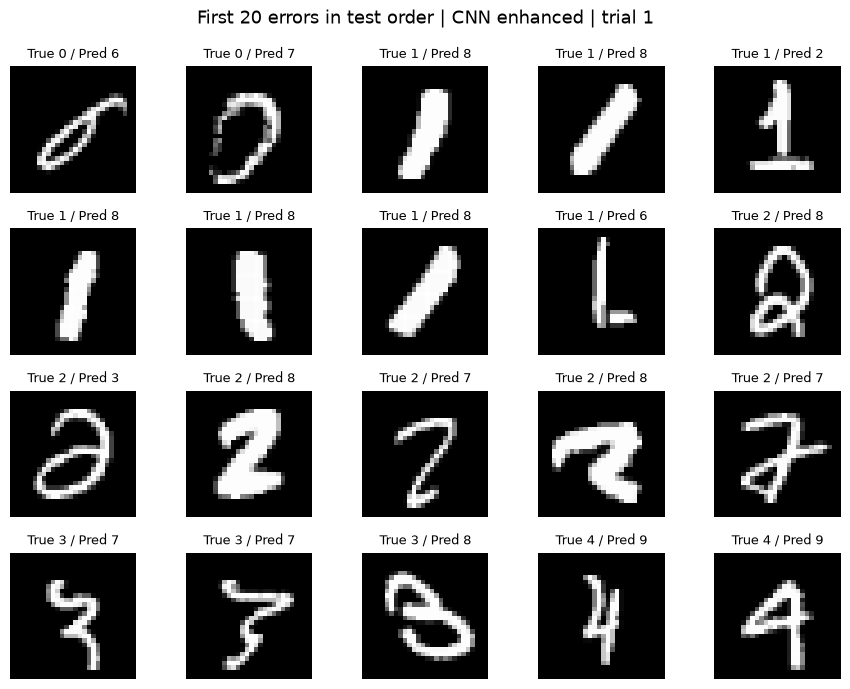

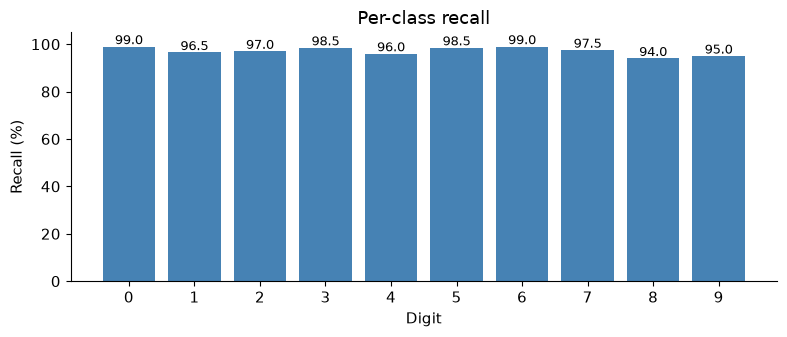

CNN enhanced trial 1 accuracy = 0.9710


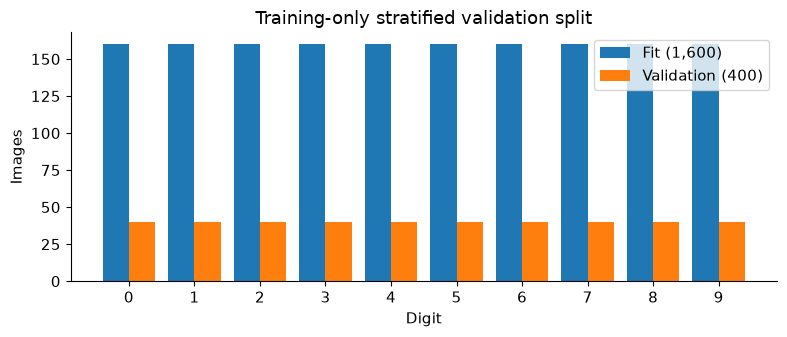


 CNN enhanced Trial 2


Epoch 01: loss 2.1928/1.8075, accuracy 0.200/0.485


Epoch 02: loss 1.6189/0.9692, accuracy 0.484/0.700


Epoch 03: loss 1.2946/0.6622, accuracy 0.584/0.797


Epoch 04: loss 1.0286/0.5071, accuracy 0.650/0.840


Epoch 05: loss 0.9154/0.4018, accuracy 0.702/0.895


... (41 outputs left out)

Epoch 47: loss 0.1648/0.0944, accuracy 0.954/0.970


Epoch 48: loss 0.1551/0.0955, accuracy 0.948/0.975


Epoch 49: loss 0.1438/0.0988, accuracy 0.958/0.965


Epoch 50: loss 0.1668/0.1025, accuracy 0.949/0.973


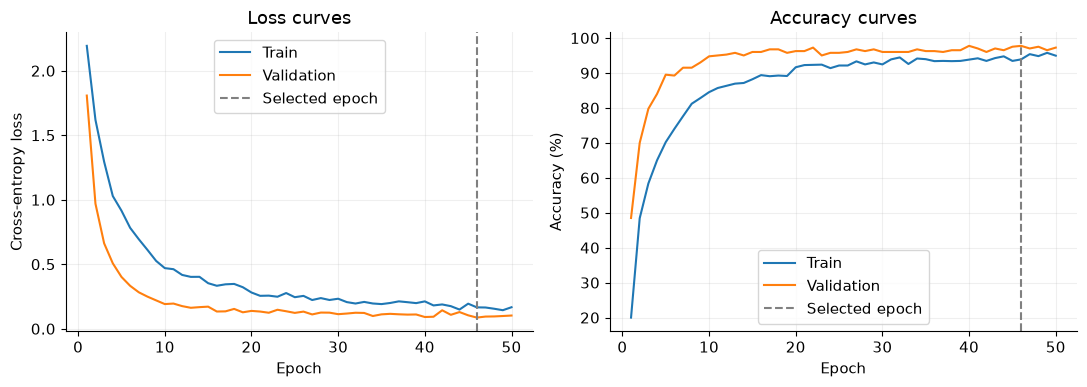

Final fit on all 2,000 training images; selected epochs: 46


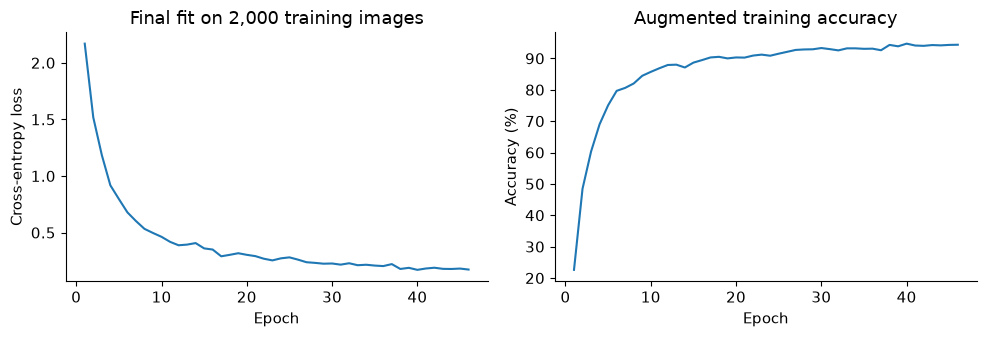

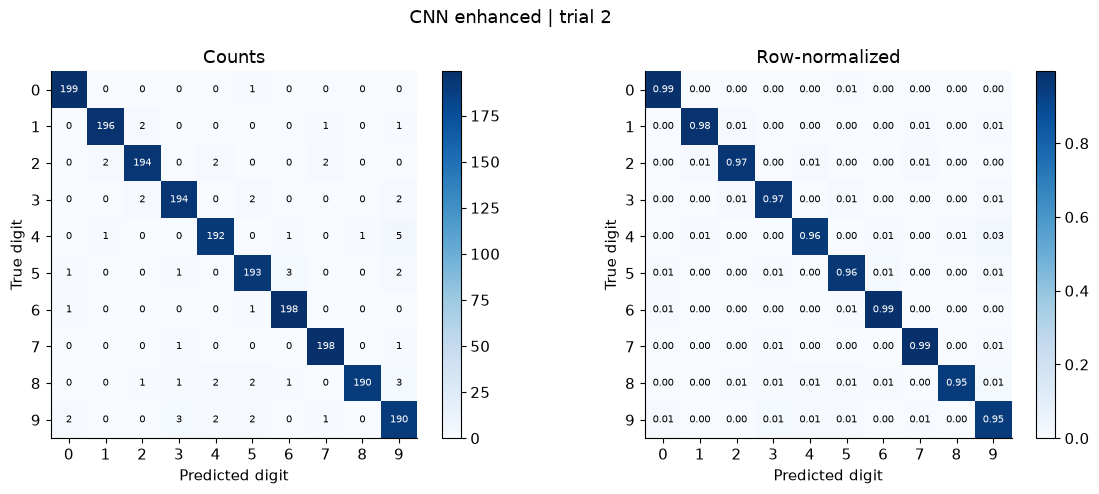

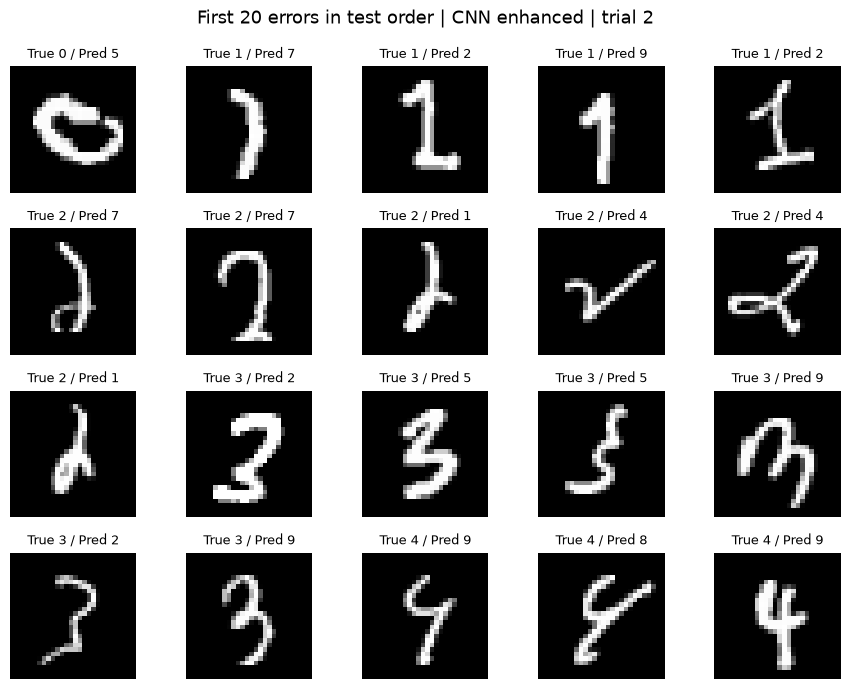

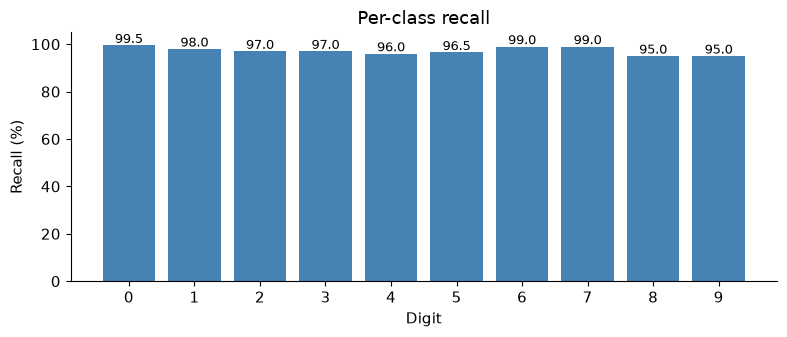

CNN enhanced trial 2 accuracy = 0.9720


,method,mean_accuracy,std_accuracy,mean_macro_f1,mean_train_seconds,mean_predict_seconds
0,CNN enhanced,0.9715,0.000707,0.971507,136.894937,0.227023


In [3]:
all_rows = []
settings = [("cnn_geometric", "CNN geometric"), ("cnn_enhanced", "CNN enhanced")]

for method_key, method_name in settings:
    method_rows = []
    for trial in [1, 2]:
        folder = output_folder(method_key, trial)
        X_train, y_train, X_test, y_test = get_trial(data, trial)
        fit, val = validation_indices(y_train, seed=SEED)
        trial_config = config.copy()
        trial_config["seed"] = SEED + trial
        if method_key == "cnn_geometric":
            trial_config["augmentation"] = experiment["geometric"].copy()
        else:
            trial_config["augmentation"] = experiment["enhanced"][str(trial)].copy()
        saved_config = trial_config.copy()
        saved_config.update({"trial": trial, "validation_fraction": 0.2, "split_seed": SEED})
        save_json(saved_config, folder / "config.json")
        np.savez(folder / "validation_indices.npz", fit=fit, validation=val,
                 original_train_indices=data["train_indices"][trial - 1])
        plot_training_split(y_train, fit, val, folder)

        print("\n", method_name, "Trial", trial)
        start = time.perf_counter()
        selected_model, history, best_epoch = train_cnn(
            X_train[fit], y_train[fit], X_train[val], y_train[val], trial_config, folder)
        selection_seconds = time.perf_counter() - start
        plot_history(history, folder)

        print("Final fit on all 2,000 training images; selected epochs:", best_epoch)
        start = time.perf_counter()
        model = fit_full_training_set(X_train, y_train, trial_config, best_epoch, folder)
        final_fit_seconds = time.perf_counter() - start
        save_json({"best_epoch": best_epoch, "best_validation_loss": float(history["val_loss"].min()),
                   "selection_seconds": selection_seconds, "final_fit_seconds": final_fit_seconds},
                  folder / "training_selection.json")

        start = time.perf_counter()
        predictions, probabilities = predict_cnn(model, X_test, trial_config)
        predict_seconds = time.perf_counter() - start
        metrics = evaluate_predictions(
            y_test, predictions, X_test, folder, method_name, trial,
            selection_seconds + final_fit_seconds, predict_seconds,
            sample_indices=data["test_indices"][trial - 1], probabilities=probabilities)
        method_rows.append(metrics)
        all_rows.append(metrics)
    display(save_method_summary(method_rows, output_folder(method_key)))

## 3. 最终结果与增强收益

只比较普通几何增强和最终增强两组，收益单位为百分点。候选方案只用训练内部验证集选择；不能根据本页的最终测试结果继续筛选方案。当前只运行一个随机种子，不能据此声称差异统计显著。以前已经查看过这份课程数据的测试结果，因此这次是迭代实验，不把它描述为全新的盲测。

,method,trial,n_test,accuracy,macro_f1,train_seconds,predict_seconds
0,CNN geometric,1,2000,0.9705,0.970561,88.058130,0.237543
1,CNN geometric,2,2000,0.9605,0.960471,53.293720,0.253772
2,CNN enhanced,1,2000,0.9710,0.971007,128.286658,0.214475
3,CNN enhanced,2,2000,0.9720,0.972006,145.503216,0.239570


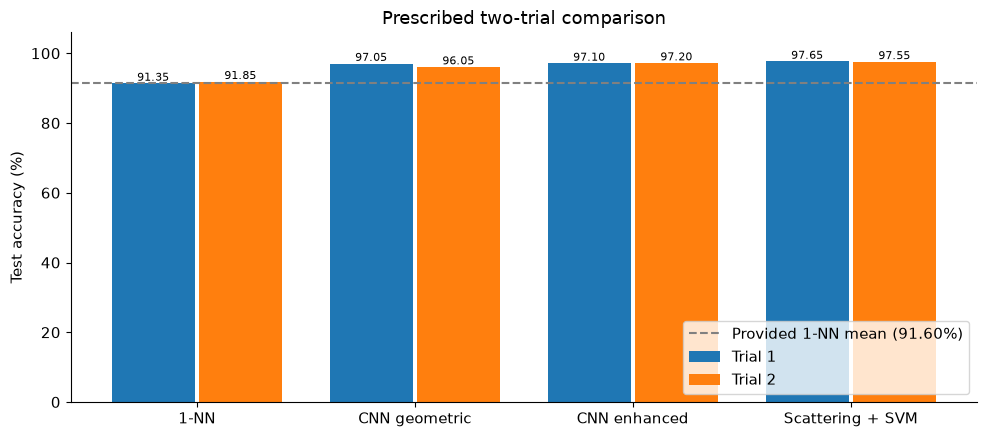

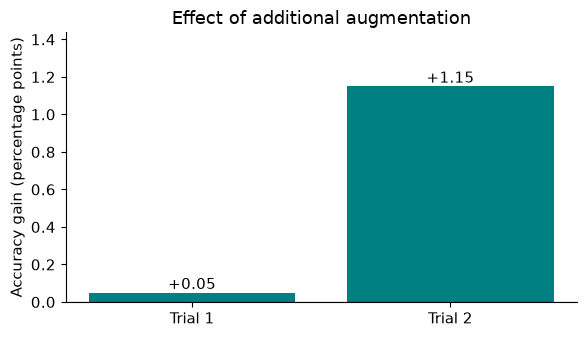

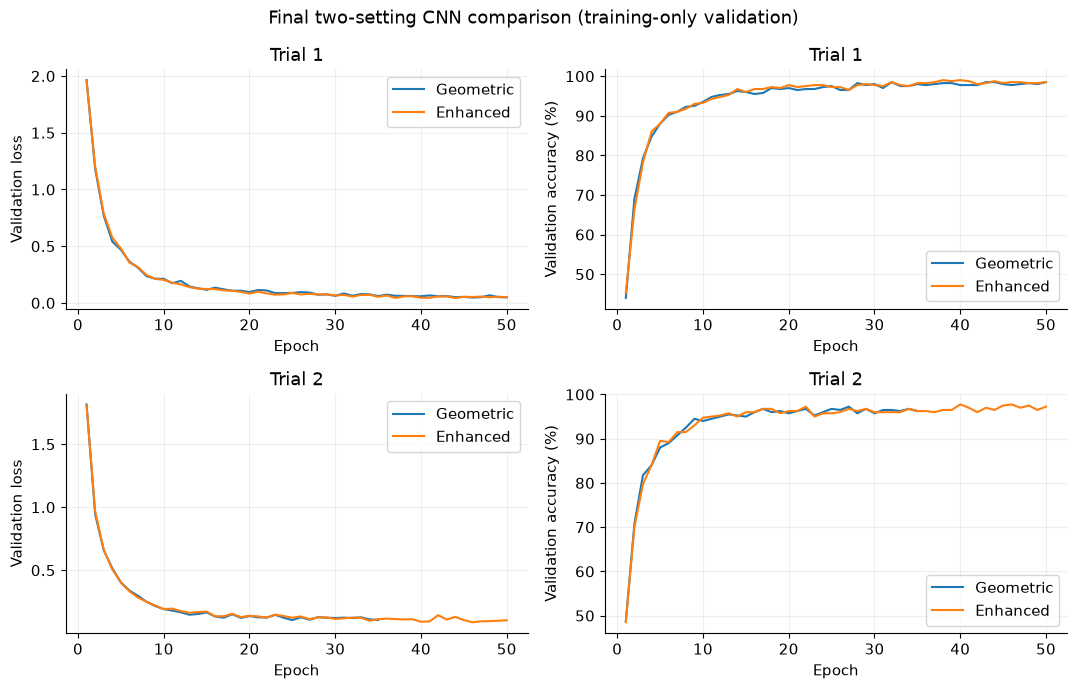

,method,mean_accuracy,std_accuracy,mean_macro_f1,mean_train_seconds,mean_predict_seconds
0,1-NN,0.9160,0.003536,0.915482,0.022998,0.132497
1,CNN geometric,0.9655,0.007071,0.965516,70.675925,0.245657
2,CNN enhanced,0.9715,0.000707,0.971507,136.894937,0.227023
3,Scattering + SVM,0.9760,0.000707,0.976011,17.928267,3.697691


In [4]:
display(pd.DataFrame(all_rows))
display(compare_methods())

## 4. 附加挑战接口

拿到老师的数据后，把 `new_images` 整理为亮字黑底、`[N,28,28]`、取值 `[0,1]` 的数组。预测时不增强；最终训练和提交方式遵守老师公布的规则。

```python
model, saved_config = load_cnn_model(output_folder("cnn_enhanced", 1) / "final_model.pt")
new_predictions, new_probabilities = predict_cnn(model, new_images, saved_config)
```

仅保留 `results/cnn_geometric/` 和 `results/cnn_enhanced/` 两组 CNN 结果，以及对应模型、配置、日志、PNG/PDF。

弹性形变参考：Simard, Steinkraus & Platt (2003), *Best Practices for Convolutional Neural Networks Applied to Visual Document Analysis*, https://www.microsoft.com/en-us/research/publication/best-practices-for-convolutional-neural-networks-applied-to-visual-document-analysis/ 。